In [2]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
from astropy.table import Table

/suphys/jfer9940/miniconda3/envs/dstools_env/lib/python3.11/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Since the first two sources I looked at didn't have any flares, I wanted to check to see just how many stars we would expect to see flares from. Given all radio flares *should* be accompanied by an optical flare, if we look for sources where we see optical flares, we should have a good chance of spotting a radio flare as well (although not guaranteed)

In [3]:
sources = Table.read('data/source_obs_data.csv')

In [4]:
sources

Simbad_ID,Archival_ra,Archival_dec,n_obs,survey_names
str19,float64,float64,int64,str67
HD 102982,177.787504285457,-51.876071495961,2,"FLASH, WALLABY"
V* V376 Cep,329.577295376914,82.870902021925,0,--
V* V815 Her,272.06734740577,29.6910259723,0,--
HD 165590A,271.457229,21.44599,0,--
HD 82533,142.67769359508,-53.521472152447,3,"EMU, GASKAP-HI"
HD 217344,345.11766870906,-33.745748964489,22,"DINGO, FLASH, WALLABY"
HD 8558,20.839329303534,-57.480907517274,2,WALLABY
HD 200244,315.742708658278,-22.933914165698,2,FLASH
HD 162186,267.778490987213,-32.307805803789,10,An ASKAP Survey for Galactic Radio Transients in the Baade's Window


In [5]:
source_names = sources['Simbad_ID'].tolist()

In [6]:
lcs = []
no_lcs = []
for src in source_names:
    lc = lk.search_lightcurve(src, author='QLP')
    if len(lc) > 0:
        lcs.append(lc.download_all().stitch())
        print(f'Appended lightcurve for {src}')
    else:
        no_lcs.append(src)
        print(f'No lightcurve found for {src}')

Appended lightcurve for HD 102982
Appended lightcurve for V* V376 Cep
Appended lightcurve for V* V815 Her
Appended lightcurve for HD 165590A


Could not resolve "HD  82533" to a sky position.


No lightcurve found for HD  82533


/suphys/jfer9940/miniconda3/envs/dstools_env/lib/python3.11/site-packages/lightkurve/lightcurve.py:1154: LightkurveWarning: The light curve appears to be zero-centered (median=1.00e+00 +/- 2.25e+00); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


Appended lightcurve for HD 217344


...

No lightcurve found for CD-75   652
Appended lightcurve for HD 205297
Appended lightcurve for HD 202917
Appended lightcurve for HD 220492


Could not resolve "HD  79551" to a sky position.


No lightcurve found for HD  79551
Appended lightcurve for V* V369 Gem


Could not resolve "HD  52118" to a sky position.


No lightcurve found for HD  52118


Some of the source names got messed up, so we just need to remove some whitespaces to get them to work as intended.

In [26]:
no_lcs

['HD  82533',
 'HD   8558',
 'HD  78644',
 'BD+21    20A',
 'CPD-55  1885',
 'HD  13183',
 'BD+66  1664',
 'BD+09  4984B',
 'CD-54  2499',
 'HD  74009B',
 'CD-31  8535',
 'CD-48  2972',
 'CD-75   652',
 'HD  79551',
 'HD  52118']

In [27]:
renamed_lcs = ['HD 82533',
 'HD 8558',
 'HD 78644',
 'BD+21 20A',
 'CPD-55 1885',
 'HD 13183',
 'BD+66 1664',
 'BD+09 4984B',
 'CD-54 2499',
 'HD 74009B',
 'CD-31 8535',
 'CD-48 2972',
 'CD-75 652',
 'HD 79551',
 'HD 52118']

In [28]:
no_lcs = []
for src in renamed_lcs:
    lc = lk.search_lightcurve(src, author='QLP')
    if len(lc) > 0:
        lcs.append(lc.download_all().stitch())
        print(f'Appended lightcurve for {src}')
    else:
        no_lcs.append(src)
        print(f'No lightcurve found for {src}')

Appended lightcurve for HD 82533
Appended lightcurve for HD 8558
Appended lightcurve for HD 78644
Appended lightcurve for BD+21 20A
Appended lightcurve for CPD-55 1885
Appended lightcurve for HD 13183
Appended lightcurve for BD+66 1664
Appended lightcurve for BD+09 4984B
Appended lightcurve for CD-54 2499
Appended lightcurve for HD 74009B
Appended lightcurve for CD-31 8535
Appended lightcurve for CD-48 2972
Appended lightcurve for CD-75 652
Appended lightcurve for HD 79551
Appended lightcurve for HD 52118


Now that we have these all downloaded, lets save them somewhere.

In [29]:
len(lcs)

41

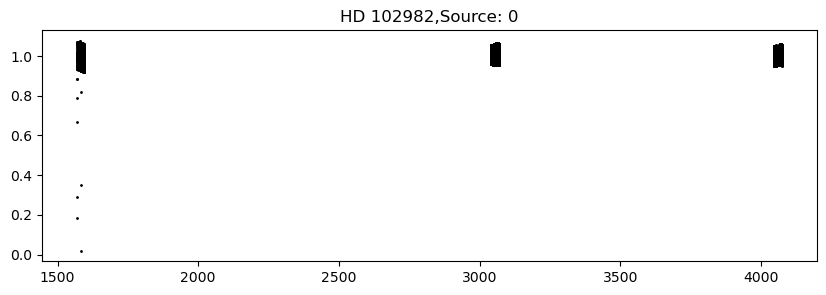

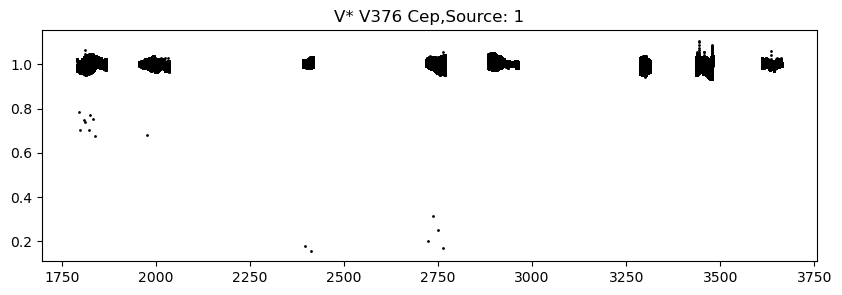

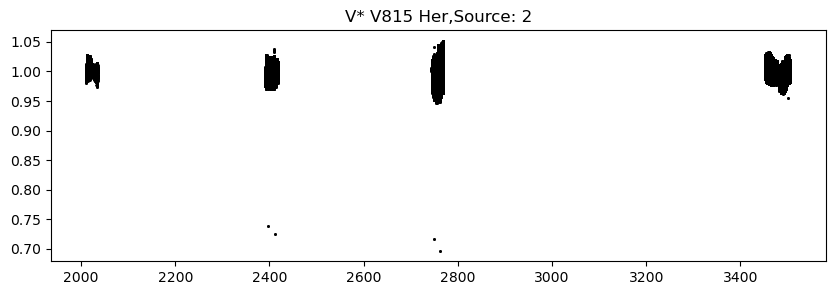

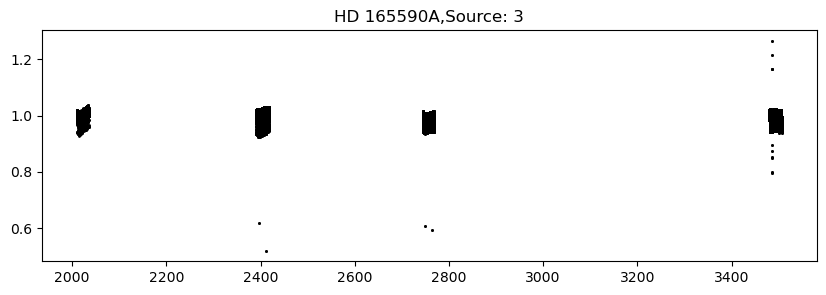

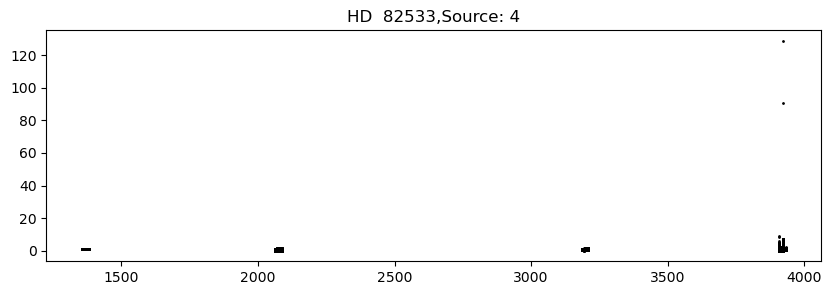

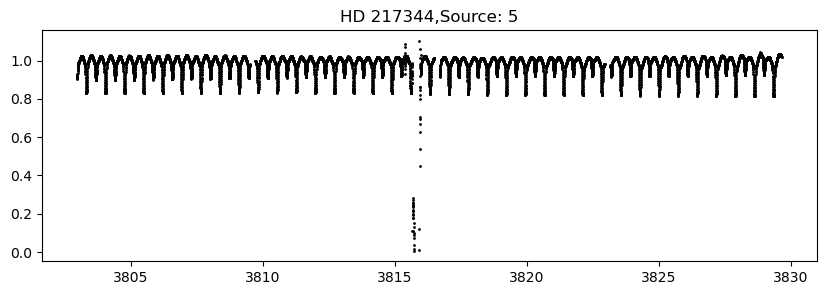

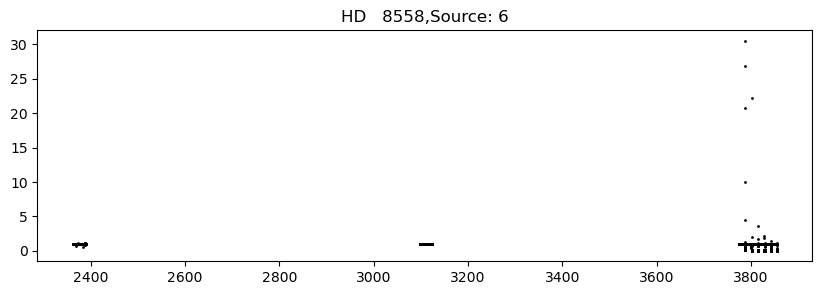

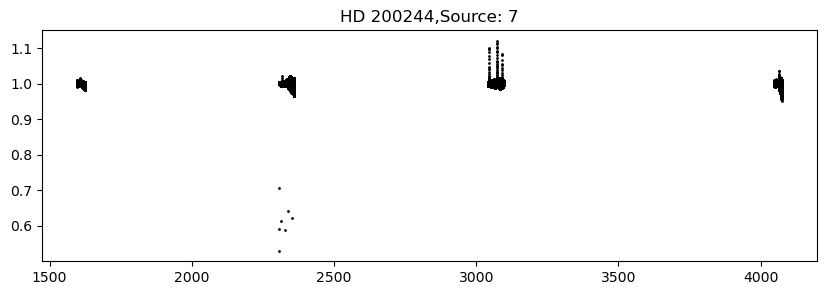

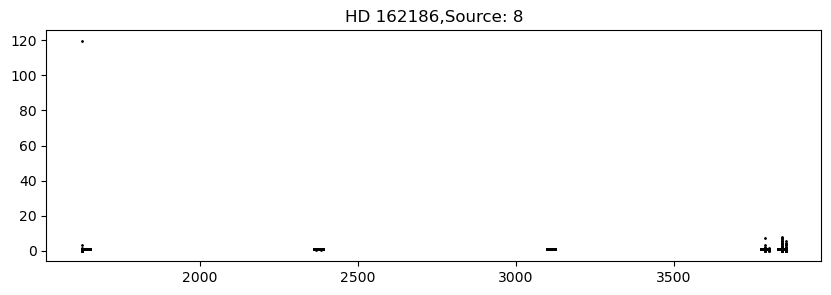

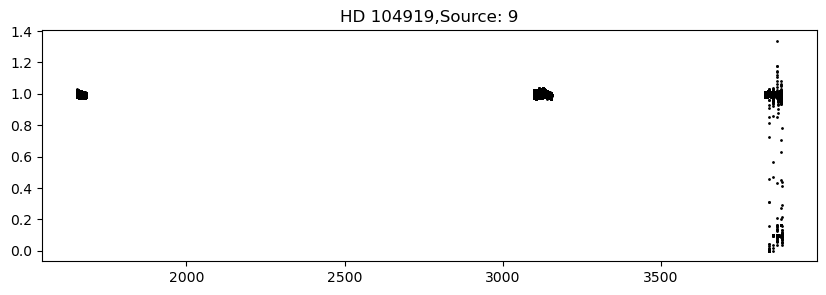

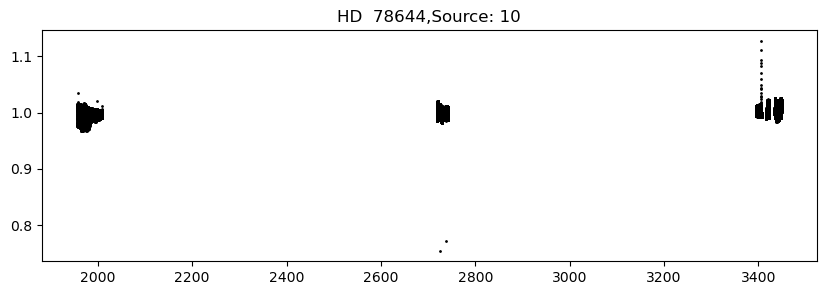

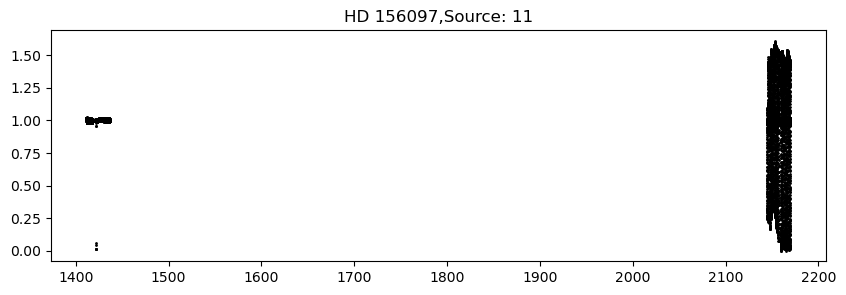

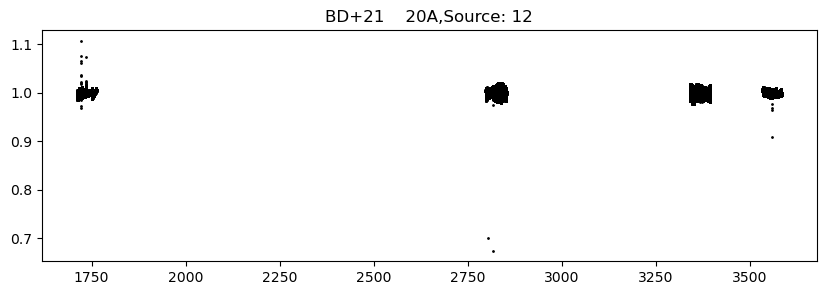

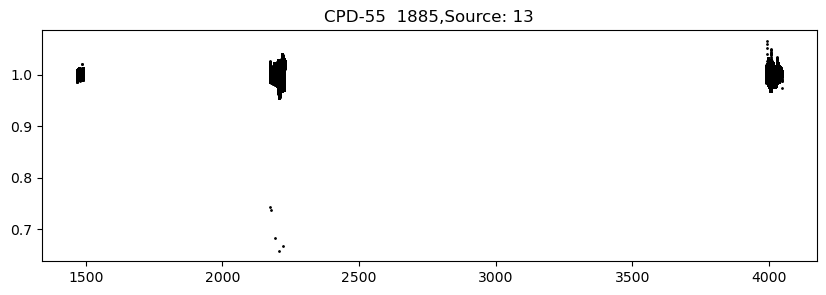

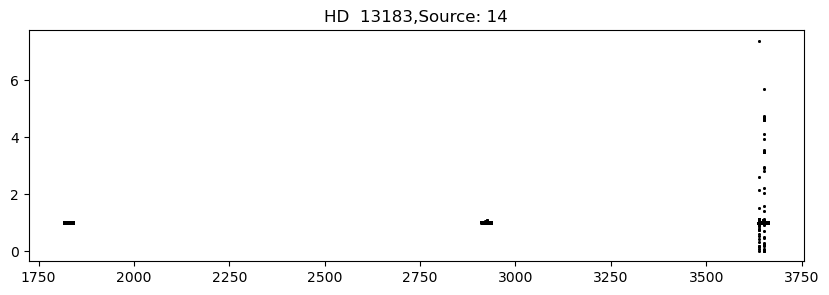

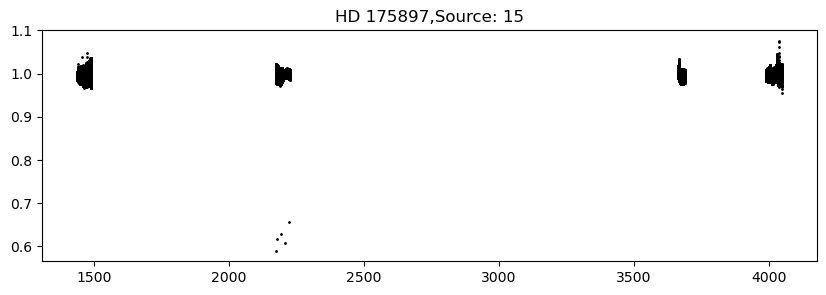

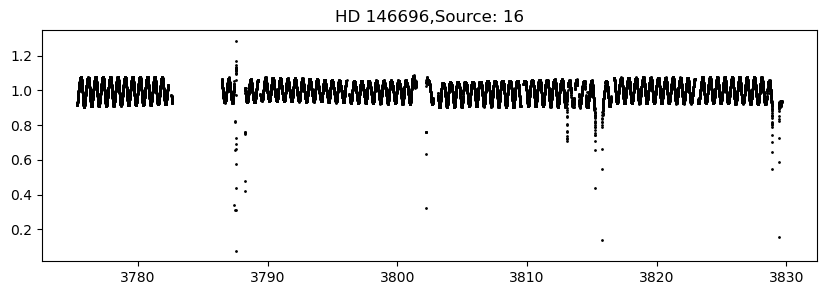

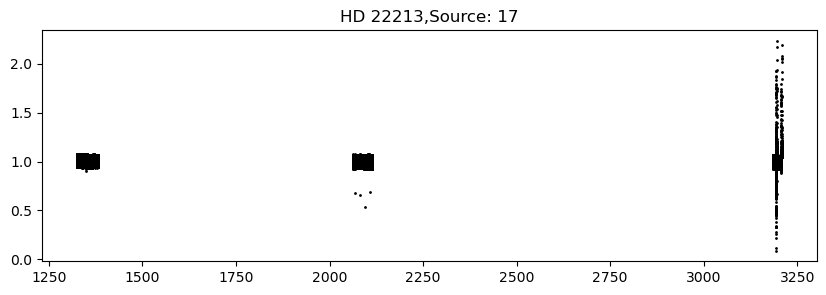

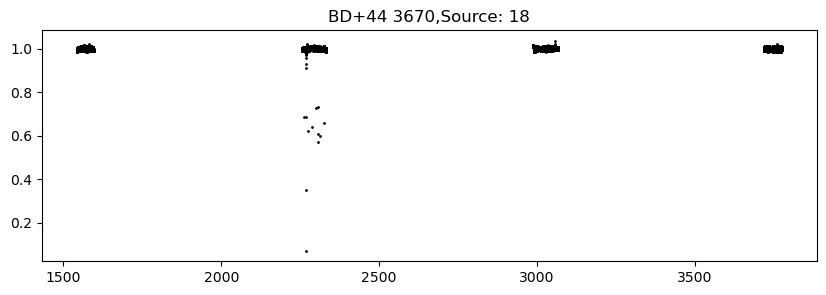

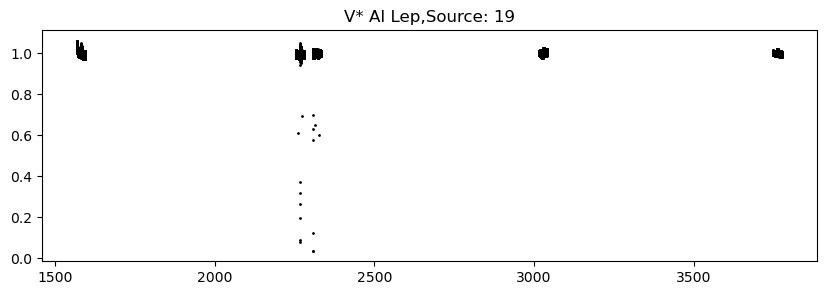

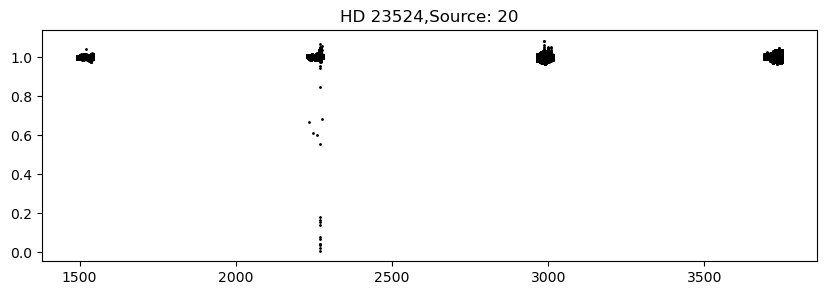

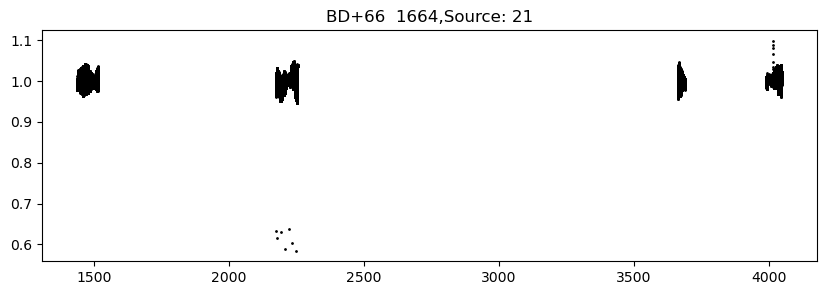

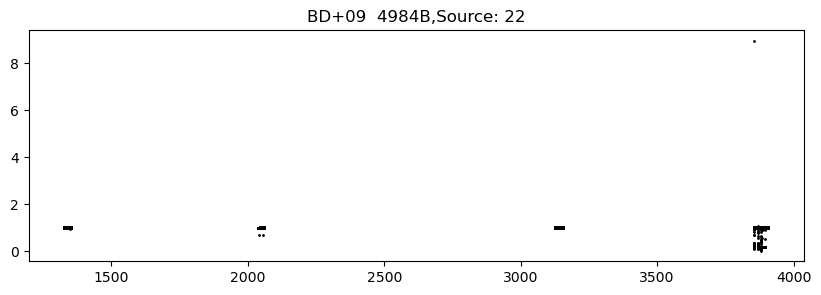

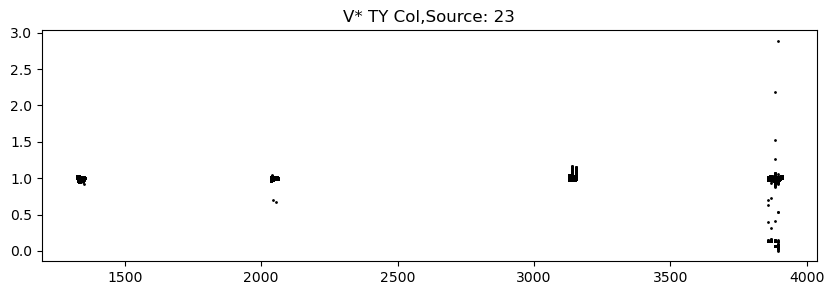

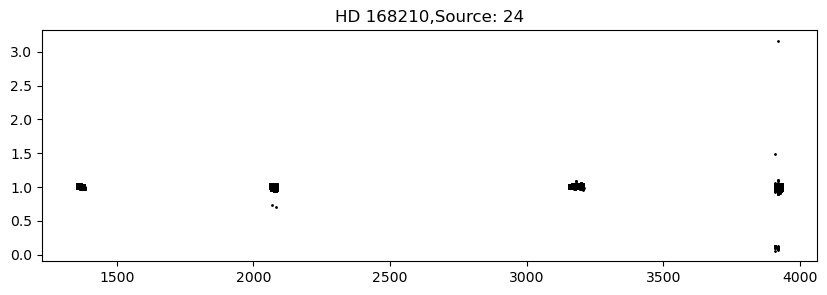

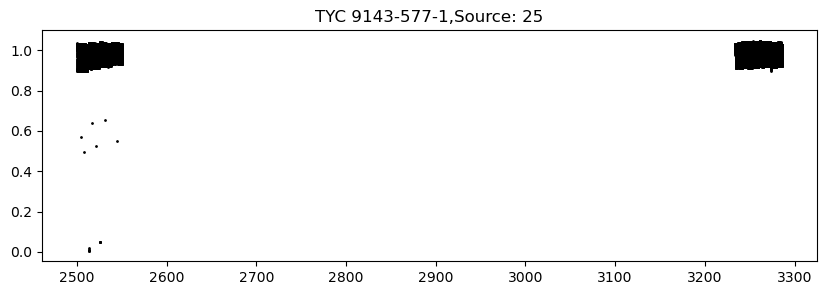

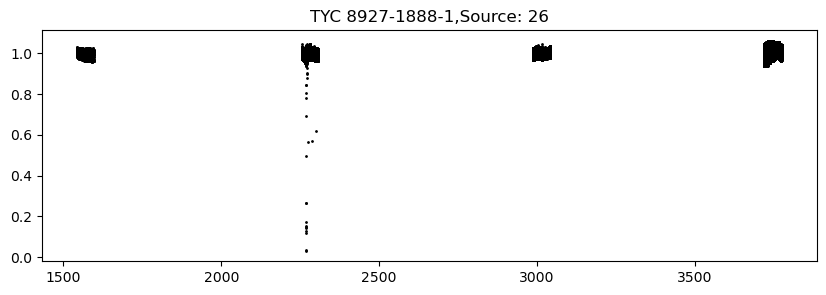

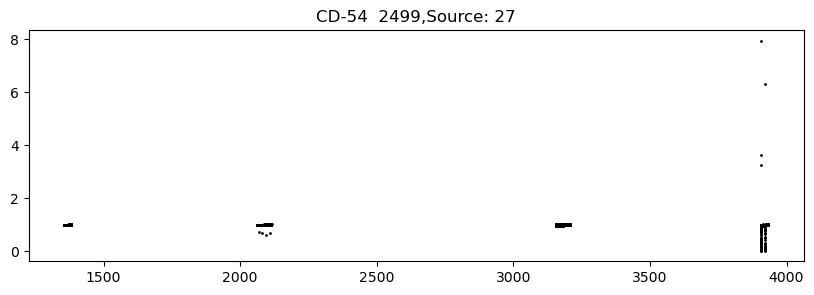

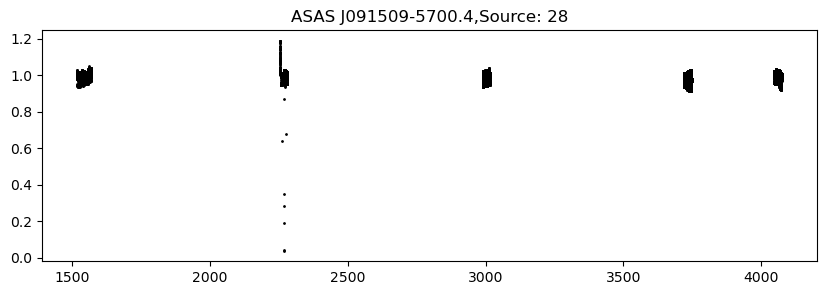

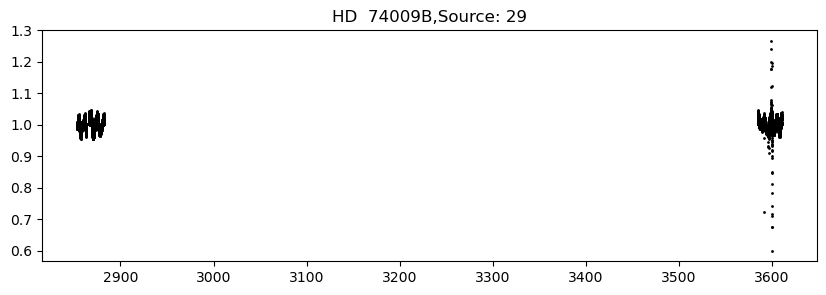

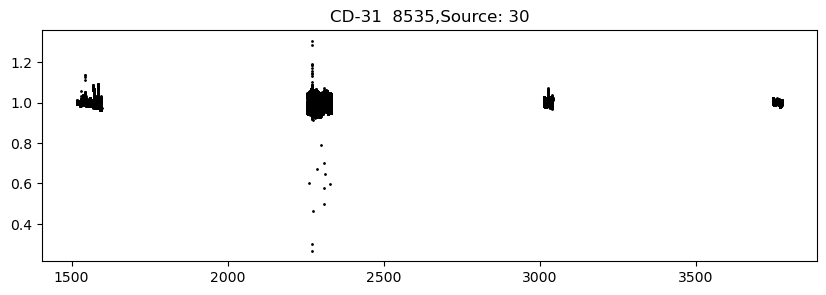

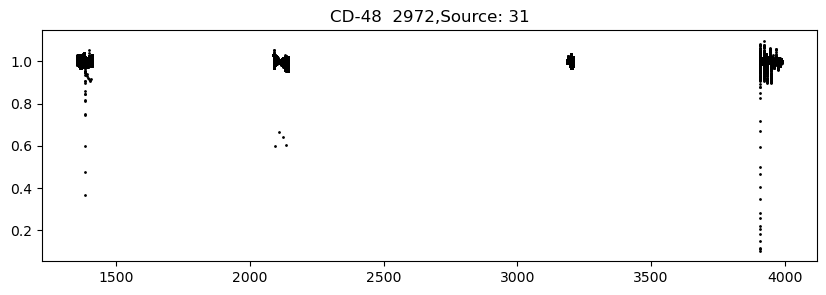

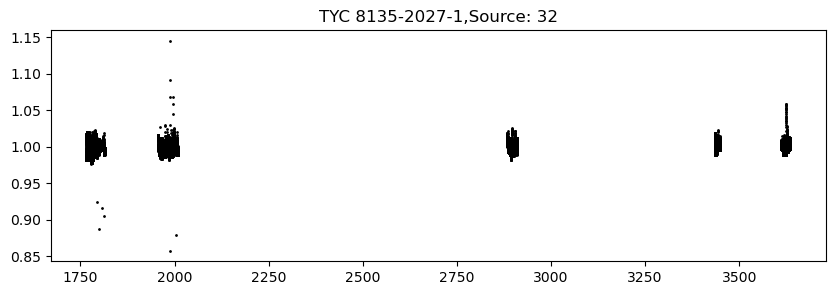

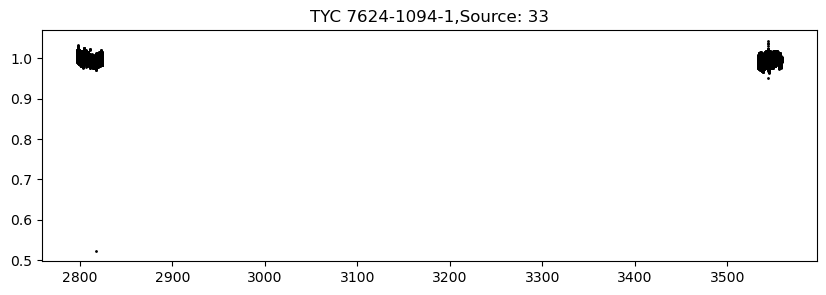

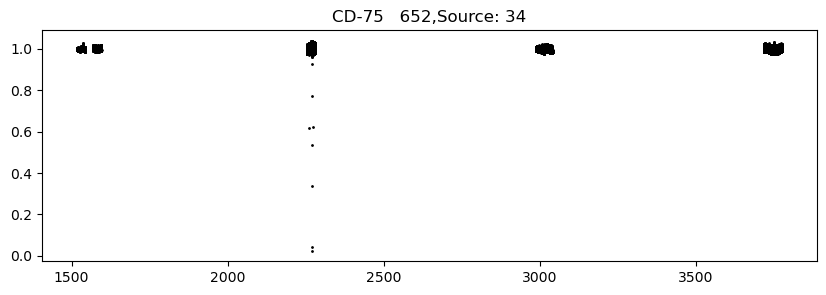

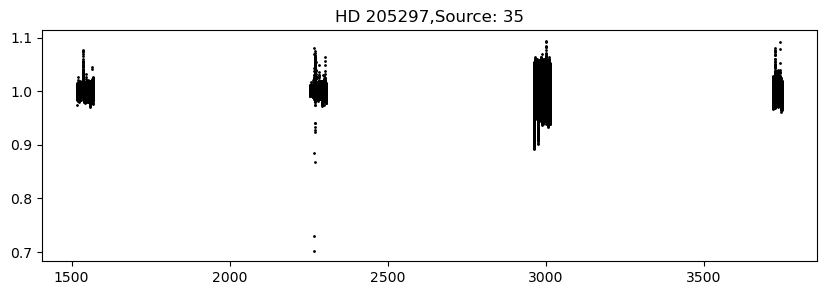

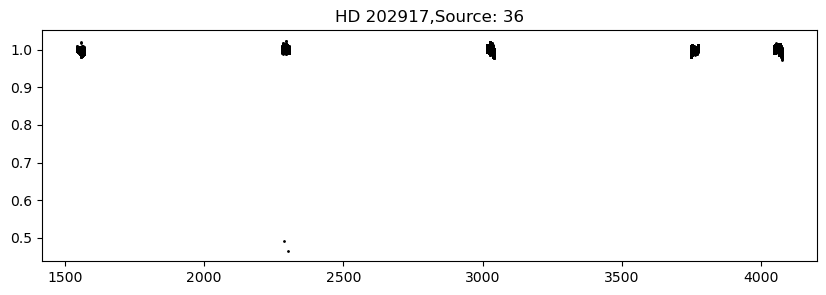

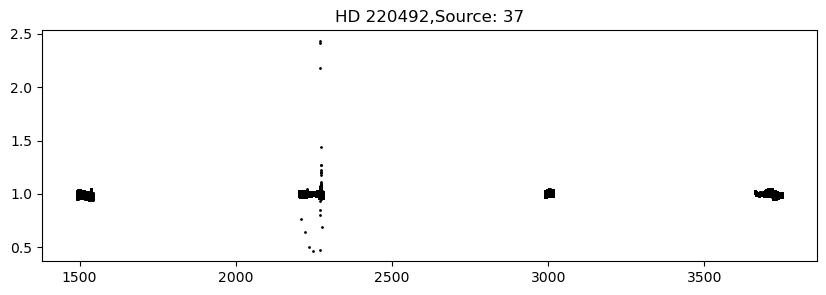

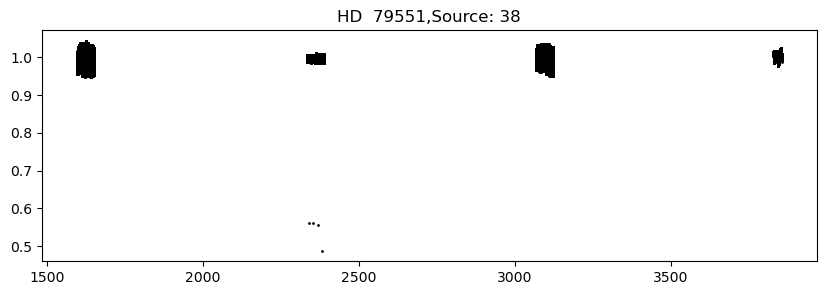

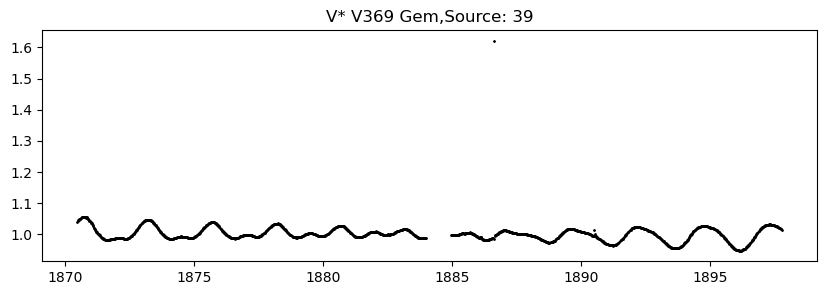

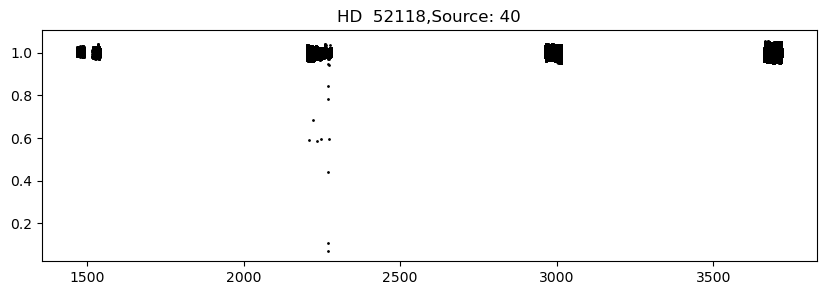

In [40]:
for i in range(0, len(lcs)):
    plt.figure(figsize = (10,3))
    plt.scatter(lcs[i]['time'].value, lcs[i]['flux'].value, s = 1, c = 'black')
    plt.title(f'{source_names[i]},Source: {i}')
    plt.show()

So it does appear there are quite a few sources that are flaring, but also quite a few that are not flaring at all. For now, I will just leave this here and not try and do any statistics.

AI Lep doesn't appear to have any flares, nor does TY Col (I think the increase being matched by a decrease is indicative of some artifacting)

In [1]:
i=7
plt.figure(figsize = (10,3))
plt.plot(lcs[i]['flux'].value, s = 1, c = 'black')
plt.title(f'{source_names[i]},Source: {i}')
plt.show()

NameError: name 'plt' is not defined